# Estudantes da rede pública do Rio de Janeiro em 2000 e 2010

**Autor** Guilherme Familiar do Amaral  
**Orientador** Alexandre Neves Louzada  
**Instituição** Centro Universitário La Salle do Rio de Janeiro (Unilasalle-RJ)  
**Disciplina** Linguagem de Programação · Sistemas de Informação · 6º período · 2026.2

A [Tabela 892 do Data.Rio](https://www.data.rio/documents/6b99c568d38646bb97dcf2751c501e7f/about) publica estimativas das amostras dos Censos Demográficos de 2000 e 2010 do IBGE. Cada aba apresenta o total da cidade e a distribuição por Região Administrativa (RA).

1. **RQ1** Como o número estimado de estudantes da rede pública mudou no município entre 2000 e 2010, por nível de ensino comparável?
2. **RQ2** Quais Regiões Administrativas tiveram os maiores aumentos e quedas no total de estudantes entre os dois censos?
3. **RQ3** Em quais Regiões Administrativas se concentrou o crescimento do número estimado de estudantes em creches públicas?

Para executar, abra este notebook dentro da pasta extraída do projeto. Selecione um kernel Python 3.12 com as dependências de `requirements.txt` instaladas, conforme o [README](../README.md).

In [1]:
from pathlib import Path
import sys

from IPython.display import Image, display
import pandas as pd

pasta_atual = Path.cwd().resolve()
raiz = next(
    (pasta for pasta in (pasta_atual, *pasta_atual.parents)
     if (pasta / "src" / "etl.py").is_file()),
    None,
)
if raiz is None:
    raise FileNotFoundError("Abra o notebook a partir da pasta extraída do projeto.")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.etl import carregar_tabela, salvar_tabela
from src.analise import (
    agregar_niveis,
    comparar_municipio,
    comparar_regioes,
    diagnosticar_cobertura,
    exportar_dados_regioes,
    exportar_figuras,
    numero_br,
    sensibilidade_penha,
)

pd.set_option("display.float_format", lambda valor: numero_br(valor, 2))
figuras = raiz / "docs" / "assets"

## 1. Ingestão, tratamento e verificação

O ETL transforma os cabeçalhos mesclados do Excel em uma tabela com uma linha por ano, território, nível e modalidade de ensino. As colunas `linha_origem` e `coluna_origem` permitem localizar cada estimativa na aba original.

Em 2000, `...` vira valor ausente. Em 2010, `-` vira zero, conforme a nota da aba. Os valores decimais de 2010 são preservados nos cálculos. As modalidades do fundamental e do médio são somadas por nível e mestrado e doutorado são reunidos para a comparação entre os anos. A soma de um nível fica ausente se alguma das parcelas estiver indisponível. Pré-vestibular e especialização permanecem no arquivo tratado, cada um no ano em que foi publicado.

In [2]:
dados = carregar_tabela()
caminho_tratado = salvar_tabela(dados)
niveis = agregar_niveis(dados)

print(f"{len(dados)} estimativas no arquivo {caminho_tratado.relative_to(raiz)}.")
display(dados.head(6))
display(dados.groupby(["ano", "status_origem"]).size().unstack(fill_value=0))

904 estimativas no arquivo data/processed/estudantes.csv.gz.


,ano,escopo,ra_codigo,territorio,nivel_ensino,modalidade,estudantes_estimados,status_origem,linha_origem,coluna_origem
0,2000,municipio,,Rio de Janeiro,Total,Total publicado,"1.004.604,00",informado,9,C
1,2000,municipio,,Rio de Janeiro,Creche,Geral,"21.799,00",informado,9,D
2,2000,municipio,,Rio de Janeiro,Pré-escola,Geral,"65.921,00",informado,9,E
3,2000,municipio,,Rio de Janeiro,Classe de alfabetização,Geral,"44.782,00",informado,9,F
4,2000,municipio,,Rio de Janeiro,Alfabetização de adultos,Geral,"6.091,00",informado,9,G
5,2000,municipio,,Rio de Janeiro,Ensino fundamental,Regular seriado,"572.090,00",informado,9,H


status_origem,indisponivel,informado,zero_explicito
ano,,,
2000,11,451,0
2010,0,427,15


In [3]:
cobertura = diagnosticar_cobertura(dados)
display(cobertura)
exportar_figuras(niveis, figuras)
caminho_regioes = exportar_dados_regioes(niveis, figuras)
print(f"Dados da tabela interativa em {caminho_regioes.relative_to(raiz)}.")

Dados da tabela interativa em docs/assets/comparacoes-regionais.js.


,regioes_publicadas,soma_regioes,total_municipal,diferenca
ano,,,,
2000,32,"1.004.408,00","1.004.604,00","−196,00"
2010,33,"1.129.833,19","1.129.833,19","0,00"


A linha do município é o total publicado. Em 2000, ela excede a soma regional em 196 estudantes. A nota da aba prevê diferenças entre totais e parcelas em dados da amostra.

A base tem 32 RAs em 2000 e 33 em 2010. Vigário Geral tem linha própria em 2010. Uma tabela municipal com o recorte populacional do Censo 2000 inclui seus quatro bairros em Penha. O Plano Diretor de 2011 apresenta as duas RAs separadas. As comparações individuais excluem Penha e Vigário Geral. A análise complementar examina o que muda ao reunir as duas RAs em 2010. [Recorte municipal de 2000](https://www.rio.rj.gov.br/dlstatic/10112/413631/DLFE-220680.pdf/1.0) · [Plano Diretor de 2011](https://www.rio.rj.gov.br/dlstatic/10112/3678296/4353007/PlanoDiretorLC111_2011)

O cálculo usa a estimativa de 2010 menos a de 2000. A variação percentual é essa diferença dividida pelo valor de 2000, quando positivo, e multiplicada por 100.

## 2. RQ1 · Mudança no município por nível de ensino

A tabela usa a linha municipal e as categorias de ensino comparáveis. O gráfico usa variações absolutas por nível.

ano,2000,2010,diferenca,variacao_pct
nivel_ensino,,,,
Total,"1.004.604,00","1.129.833,19","125.229,19","12,47"
Creche,"21.799,00","47.705,89","25.906,89","118,84"
Pré-escola,"65.921,00","62.276,80","−3.644,20","−5,53"
Classe de alfabetização,"44.782,00","67.839,38","23.057,38","51,49"
Alfabetização de adultos,"6.091,00","16.912,39","10.821,39","177,66"
Ensino fundamental,"613.400,00","577.404,48","−35.995,52","−5,87"
Ensino médio,"186.467,00","259.081,76","72.614,76","38,94"
Graduação,"54.998,00","79.434,75","24.436,75","44,43"
Mestrado e doutorado,"8.981,00","12.103,75","3.122,75","34,77"


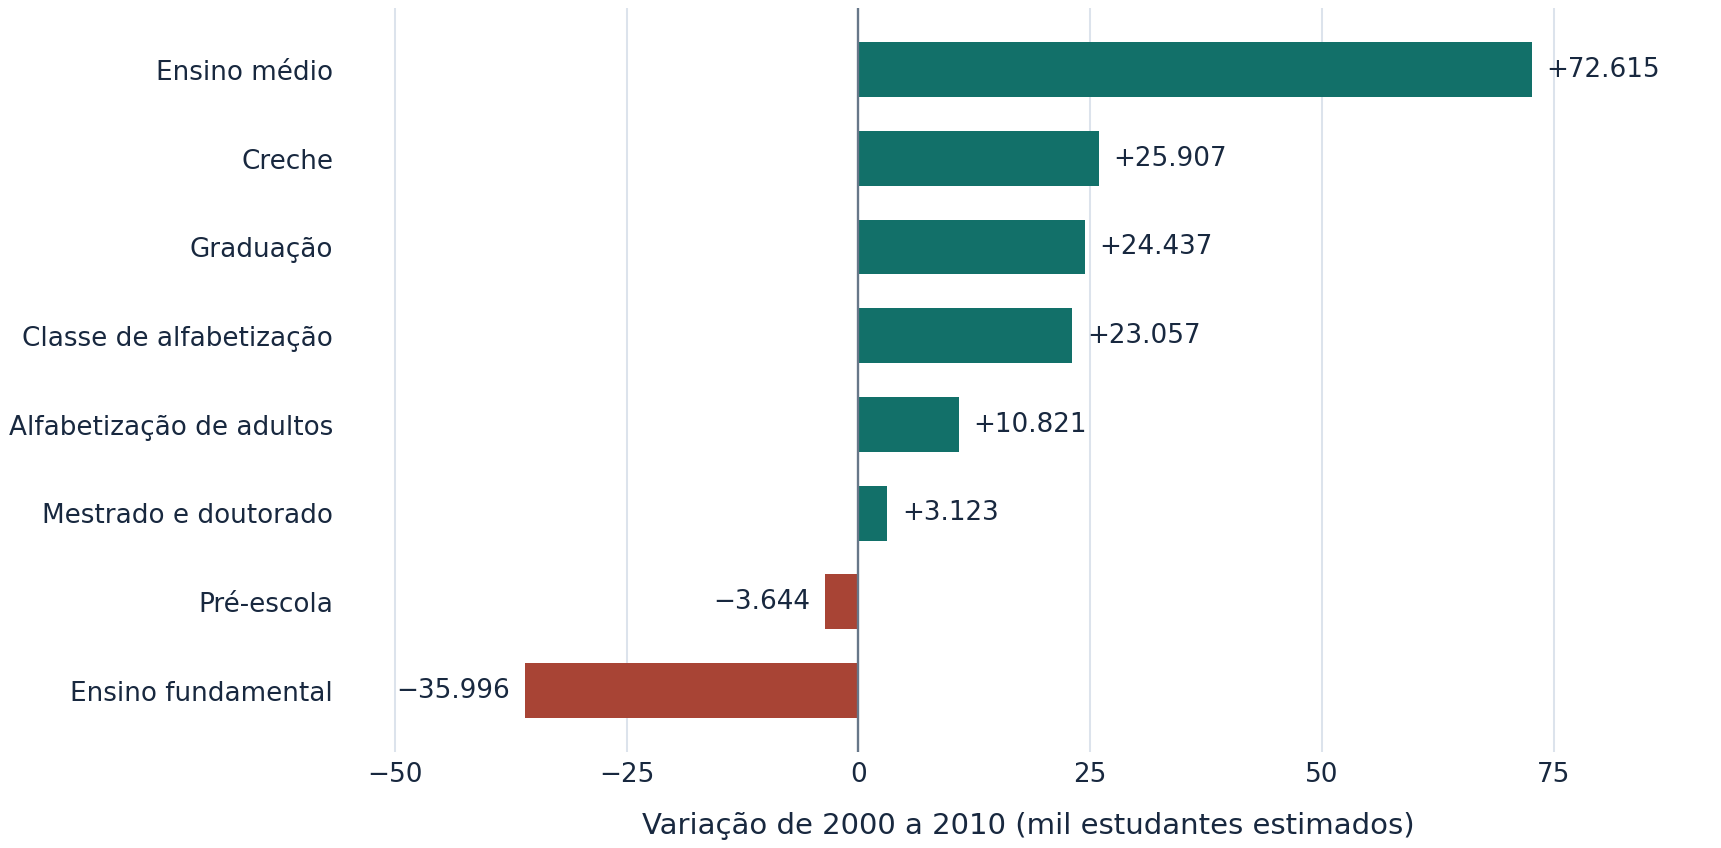

In [4]:
municipio = comparar_municipio(niveis)
display(municipio)
display(Image(filename=str(figuras / "variacao-niveis.png"), width=760))

O total municipal passou de 1.004.604 para cerca de 1.129.833 estudantes (+12,5%). O ensino médio teve o maior ganho absoluto (+72.615). O fundamental permaneceu como o nível com mais estudantes e registrou a maior queda absoluta (−35.996). A alfabetização de adultos teve a maior alta percentual (+177,7%) a partir de 6.091 estudantes em 2000. Valores de apresentação arredondados.

## 3. RQ2 · Maiores mudanças no total por RA

O ranking usa as 31 regiões com valores comparáveis. As duas tabelas mostram as cinco maiores altas e quedas por diferença absoluta.

23 altas e 8 quedas em 31 RAs.
Mediana +2.334. Metade central entre −95 e +6.501.
Maior alta percentual em Barra da Tijuca (+73,7%). Maior queda percentual em Ilha do Governador (−8,1%).


,ano,2000,2010,diferenca,variacao_pct
ra_codigo,territorio,,,,
XVI,Jacarepaguá,"78.655,00","95.514,88","16.859,88","21,44"
XIX,Santa Cruz,"77.129,00","91.355,67","14.226,67","18,45"
XXIV,Barra da Tijuca,"18.302,00","31.782,18","13.480,18","73,65"
XXX,Maré,"23.999,00","35.448,68","11.449,68","47,71"
XXV,Pavuna,"41.609,00","51.065,97","9.456,97","22,73"


,ano,2000,2010,diferenca,variacao_pct
ra_codigo,territorio,,,,
XVII,Bangu,"89.697,00","86.565,57","−3.131,43","−3,49"
XXXIII,Realengo,"47.656,00","44.559,06","−3.096,94","−6,50"
XX,Ilha do Governador,"33.229,00","30.551,48","−2.677,52","−8,06"
XV,Madureira,"64.452,00","62.504,83","−1.947,17","−3,02"
IV,Botafogo,"22.816,00","21.240,39","−1.575,61","−6,91"


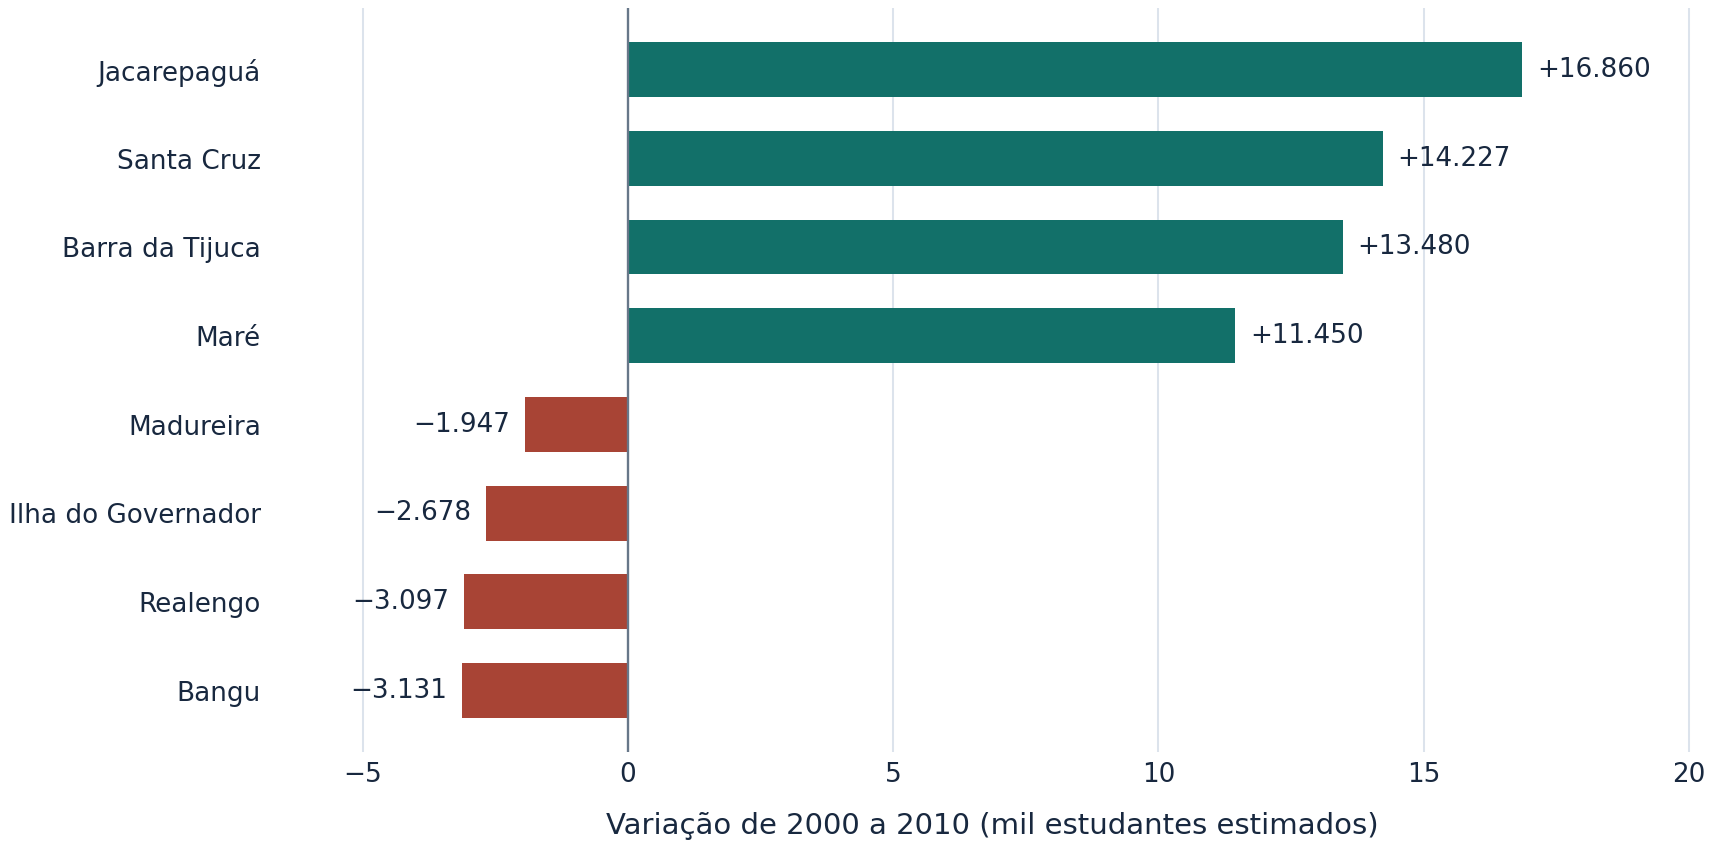

In [5]:
regioes = comparar_regioes(niveis, "Total")
altas = regioes.loc[regioes["diferenca"] > 0]
quedas = regioes.loc[regioes["diferenca"] < 0].sort_values("diferenca")
quartis = regioes["diferenca"].quantile([0.25, 0.50, 0.75])
percentual = regioes["variacao_pct"]
maior_alta = percentual.idxmax()
maior_queda = percentual.idxmin()

print(f"{len(altas)} altas e {len(quedas)} quedas em {len(regioes)} RAs.")
print(
    f"Mediana {numero_br(quartis.loc[0.50], sinal=True)}. "
    f"Metade central entre {numero_br(quartis.loc[0.25], sinal=True)} "
    f"e {numero_br(quartis.loc[0.75], sinal=True)}."
)
print(
    f"Maior alta percentual em {maior_alta[1]} ({numero_br(percentual.loc[maior_alta], 1, True)}%). "
    f"Maior queda percentual em {maior_queda[1]} ({numero_br(percentual.loc[maior_queda], 1, True)}%)."
)
display(altas.head(5))
display(quedas.head(5))
display(Image(filename=str(figuras / "variacao-regioes.png"), width=760))

In [6]:
print("Penha em 2000 e Penha somada a Vigário Geral em 2010")
display(sensibilidade_penha(niveis))

Penha em 2000 e Penha somada a Vigário Geral em 2010


ano,2000,2010,diferenca,variacao_pct
nivel_ensino,,,,
Total,"55.607,00","65.462,48","9.855,48","17,72"
Creche,"791,00","2.444,58","1.653,58","209,05"


Jacarepaguá liderou as altas absolutas (+16.860), seguida de Santa Cruz e Barra da Tijuca. Bangu teve a maior queda absoluta (−3.131). Barra da Tijuca teve o maior aumento percentual (+73,7%) e Ilha do Governador, a maior queda percentual (−8,1%). No exercício complementar, o total de Penha em 2000 passa de 55.607 para cerca de 65.462 ao somar Penha e Vigário Geral em 2010 (+17,7%). Esse resultado depende da hipótese de recortes equivalentes.

## 4. RQ3 · Distribuição do crescimento em creche

O ranking usa o ganho absoluto em creche. A participação das três maiores altas usa como denominador a soma dos aumentos das RAs comparadas.

31 de 31 RAs tiveram alta.
As três maiores altas somam 29,2% do aumento nas RAs comparadas.


,ano,2000,2010,diferenca,variacao_pct
ra_codigo,territorio,,,,
XIX,Santa Cruz,"3.308,00","6.109,82","2.801,82","84,70"
XVIII,Campo Grande,"1.274,00","3.568,37","2.294,37","180,09"
XVI,Jacarepaguá,"1.328,00","3.325,70","1.997,70","150,43"
XVII,Bangu,"1.764,00","3.203,55","1.439,55","81,61"
XXV,Pavuna,"909,00","2.315,74","1.406,74","154,76"
XV,Madureira,"1.128,00","2.419,98","1.291,98","114,54"
XXVII,Rocinha,"430,00","1.537,15","1.107,15","257,48"


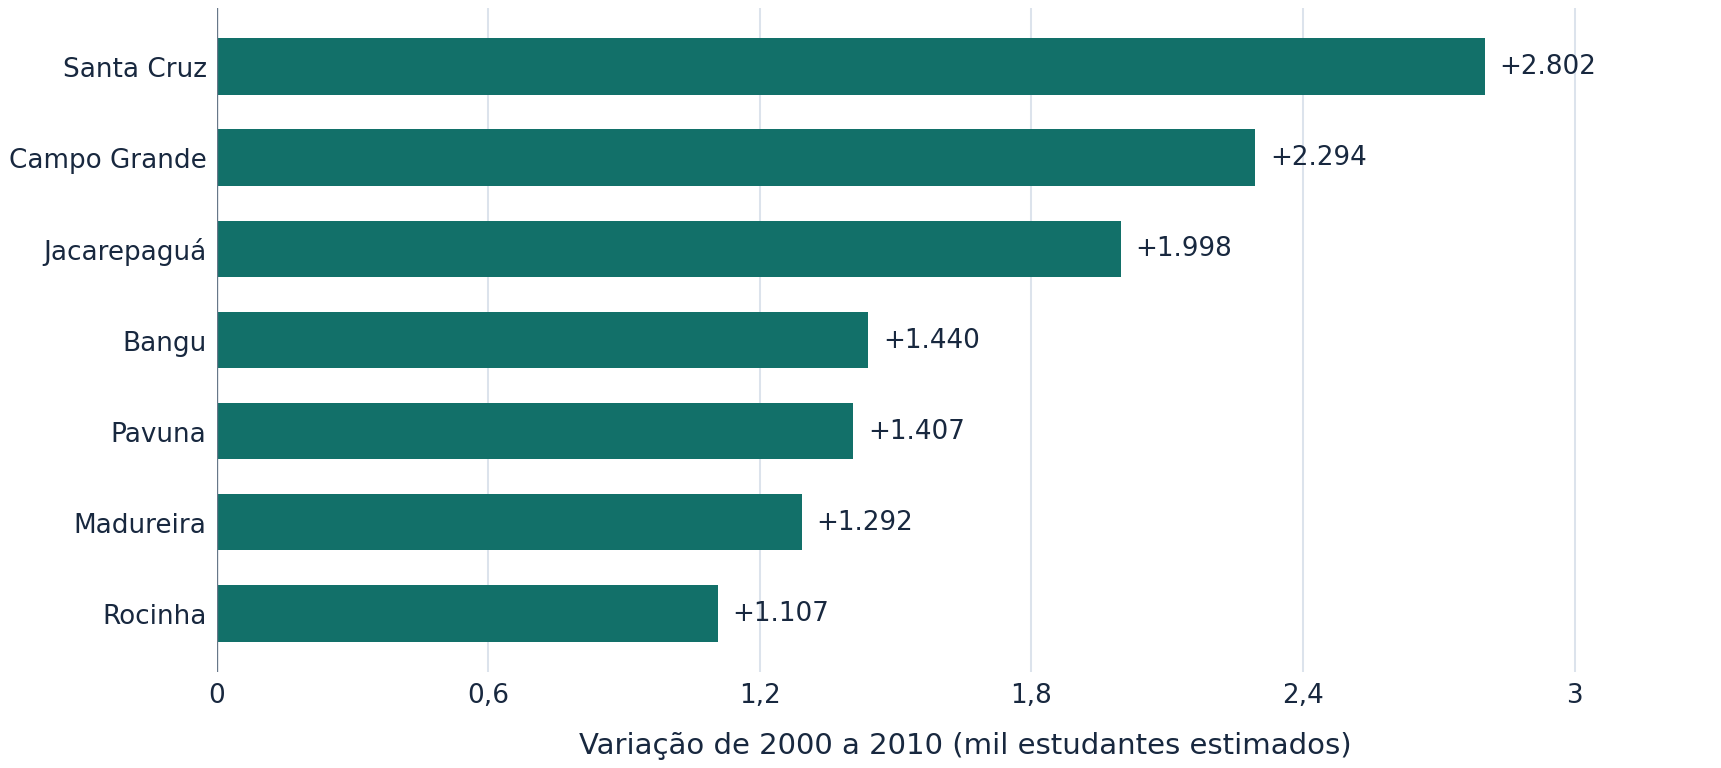

In [7]:
creche = comparar_regioes(niveis, "Creche")
diferencas = creche["diferenca"]
participacao = diferencas.head(3).sum() / diferencas.sum() * 100

print(f"{(diferencas > 0).sum()} de {len(creche)} RAs tiveram alta.")
print(f"As três maiores altas somam {numero_br(participacao, 1)}% do aumento nas RAs comparadas.")
display(creche.head(7))
display(Image(filename=str(figuras / "variacao-creche.png"), width=760))

## 5. Síntese e limitações

O município registrou aumento no total estimado, com o maior ganho absoluto no ensino médio. Entre as RAs comparadas, Jacarepaguá liderou o crescimento no total e Santa Cruz em creche. A alta em creche ocorreu nas 31 RAs da comparação, com 29,2% do aumento concentrado em Santa Cruz, Campo Grande e Jacarepaguá.

O estudo compara dois anos censitários e usa estimativas amostrais. Os resultados descrevem volumes estimados. Para avaliar cobertura educacional seriam necessários denominadores por faixa etária. Para testar diferenças estatísticas seriam necessárias medidas de incerteza do desenho amostral.

O [artigo](../docs/index.html) apresenta os resultados e os princípios FAIR. O [dicionário de dados](../data/data_dictionary.md) registra o significado das variáveis e a atribuição da base CC BY 4.0.